# Figure 4

In [1]:
import os
import sys
sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["pdf.fonttype"] = 42   # keep text editable in Illustrator
plt.rcParams["ps.fonttype"] = 42

from data_io import load_cells, load_traces, load_roi_coordinates
cells = load_cells()
FI = 0.806                    # s per volume
DATASETS = ["P2P3", "P6P7"]
from scipy.stats import mannwhitneyu
FIG = "../figures/Fig4"
os.makedirs(FIG, exist_ok=True)
norm_df = pd.read_parquet("../data/cell_features.parquet")
FEATURES = ["median_duration_s", "n_subpeaks", "median_interpeak_interval_s", "tau_s"]
LABELS = {"median_duration_s": "Episode\nDuration (s)", "n_subpeaks": "Number\nof Peaks",
          "median_interpeak_interval_s": "Interpeak\nInterval (s)", "tau_s": "Autocorrelation\nTau (s)"}
GROUP_LABELS = {"P2P3": "P2/P3", "P6P7": "P6/P7"}
COLORS = {"P2P3": "#2a78d6", "P6P7": "#eb6834"}


def cliffs_delta(x, y):
    d = x[:, None] - y[None, :]
    return (np.sum(d > 0) - np.sum(d < 0)) / (len(x) * len(y))

rows = []
for f in FEATURES:
    sub = norm_df[["dataset", "ant", f]].dropna()
    pa = sub.groupby(["dataset", "ant"])[f].median().reset_index()
    young = pa.loc[pa.dataset == "P2P3", f].values; old = pa.loc[pa.dataset == "P6P7", f].values
    yc = sub.loc[sub.dataset == "P2P3", f].values; oc = sub.loc[sub.dataset == "P6P7", f].values
    rows.append({"feature": f, "p2p3_pupa_medians": np.round(np.sort(young), 2).tolist(), "p6p7_pupa_medians": np.round(np.sort(old), 2).tolist(),
                 "cliffs_delta_P6P7_vs_P2P3": cliffs_delta(oc, yc), "p_mann_whitney": mannwhitneyu(young, old, alternative="two-sided").pvalue})
age_df = pd.DataFrame(rows)
age_df.to_csv("../data/features_by_age_summary.csv", index=False)
age_df

,feature,p2p3_pupa_medians,p6p7_pupa_medians,cliffs_delta_P6P7_vs_P2P3,p_mann_whitney
0,median_duration_s,"[368.74, 378.42, 408.64, 432.02, 487.63]","[684.7, 759.25, 785.04, 860.81, 1170.31]",0.614179,0.007937
1,n_subpeaks,"[12.0, 13.0, 14.0, 15.0, 16.5]","[6.0, 7.0, 8.0, 9.0, 10.0]",-0.401170,0.007937
2,median_interpeak_interval_s,"[267.59, 281.29, 309.5, 332.07, 349.0]","[455.39, 494.48, 498.11, 642.38, 658.9]",0.382884,0.007937
3,tau_s,"[180.54, 188.6, 194.25, 207.95, 208.75]","[270.82, 280.89, 290.16, 305.47, 307.89]",0.324828,0.007937


## Panels A–B

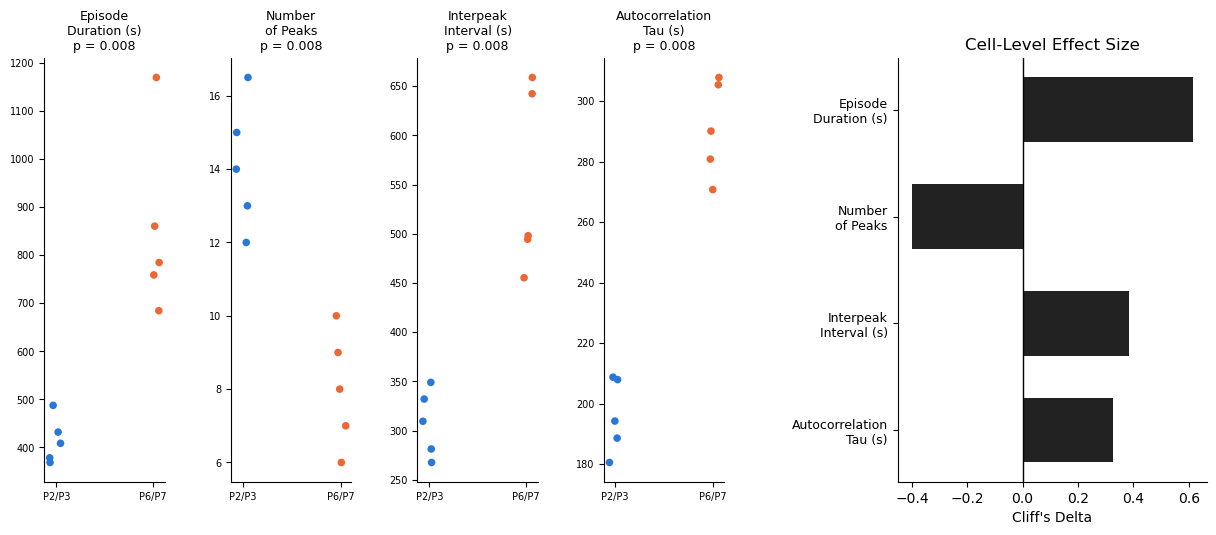

In [2]:
pa_all = norm_df.groupby(["dataset", "ant"])[FEATURES].median().reset_index()
fig = plt.figure(figsize=(15, 5.5))
grid = fig.add_gridspec(1, 2, width_ratios=[2.2, 1], wspace=0.35)
grid_a = grid[0].subgridspec(1, len(FEATURES), wspace=0.55)
rng = np.random.default_rng(0)
for i, f in enumerate(FEATURES):
    ax = fig.add_subplot(grid_a[i])
    for j, d in enumerate(["P2P3", "P6P7"]):
        vals = pa_all.loc[pa_all.dataset == d, f].values
        ax.scatter(np.full(len(vals), j) + rng.uniform(-0.07, 0.07, len(vals)), vals, s=30, color=COLORS[d], edgecolors="none")
    p = age_df.loc[age_df.feature == f, "p_mann_whitney"].iloc[0]
    ax.set_title(f"{LABELS[f]}\np = {p:.3f}", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels([GROUP_LABELS["P2P3"], GROUP_LABELS["P6P7"]], fontsize=8); ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
ax = fig.add_subplot(grid[1])
ypos = np.arange(len(FEATURES))[::-1]
ax.barh(ypos, age_df.set_index("feature").loc[FEATURES, "cliffs_delta_P6P7_vs_P2P3"], color="#222222", height=0.6)
ax.axvline(0, color="black", lw=1); ax.set_yticks(ypos); ax.set_yticklabels([LABELS[f] for f in FEATURES], fontsize=9)
ax.set_xlabel("Cliff's Delta"); ax.set_title("Cell-Level Effect Size")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(f"{FIG}/Fig4AB_features_by_age.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/Fig4AB_features_by_age.eps", bbox_inches="tight")

## Panel C

per-pupa medians: P2P3 median 0.493 (range 0.469-0.574); P6P7 median 0.572 (range 0.554-0.621); p = 0.0556


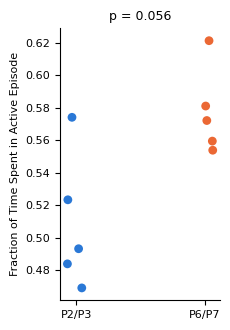

In [3]:
pa_duty = norm_df.groupby(["dataset", "ant"])["duty_cycle"].median().reset_index()
young_d = pa_duty.loc[pa_duty.dataset == "P2P3", "duty_cycle"].values
old_d = pa_duty.loc[pa_duty.dataset == "P6P7", "duty_cycle"].values
p_duty = mannwhitneyu(young_d, old_d, alternative="two-sided").pvalue
print(f"per-pupa medians: P2P3 median {np.median(young_d):.3f} (range {young_d.min():.3f}-{young_d.max():.3f}); "
      f"P6P7 median {np.median(old_d):.3f} (range {old_d.min():.3f}-{old_d.max():.3f}); p = {p_duty:.4f}")
fig, ax = plt.subplots(figsize=(2.4, 3.4))
rng = np.random.default_rng(0)
for j, d in enumerate(["P2P3", "P6P7"]):
    vals = pa_duty.loc[pa_duty.dataset == d, "duty_cycle"].values
    ax.scatter(np.full(len(vals), j) + rng.uniform(-0.07, 0.07, len(vals)), vals, s=40, color=COLORS[d], edgecolors="none")
ax.set_xticks([0, 1]); ax.set_xticklabels([GROUP_LABELS["P2P3"], GROUP_LABELS["P6P7"]], fontsize=8)
ax.set_ylabel("Fraction of Time Spent in Active Episode", fontsize=8); ax.set_title(f"p = {p_duty:.3f}", fontsize=9)
ax.tick_params(labelsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/Fig4C_duty_cycle.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/Fig4C_duty_cycle.eps", bbox_inches="tight")